Obtain and view datasets

File Paths

In [77]:
import pandas as pd
USER_PRODUCTS_FILE = "processed/user_prior_products.parquet"
PRODUCT_LOOKUP_FILE = "processed/products_lookup.parquet"
OUTPUT_FILE = "processed/user_features.parquet"

Load Data

In [78]:
print("Loading data...")

user_products = pd.read_parquet(USER_PRODUCTS_FILE)
products = pd.read_parquet(PRODUCT_LOOKUP_FILE)

print(f"Users loaded: {len(user_products):,}")
print(f"Products loaded: {len(products):,}")

Loading data...
Users loaded: 206,209
Products loaded: 49,685


Feature Engineering. Keeps only columns required for clustering
Before:

user_id    product_id
1          [196, 14084, 12427, ...]

After:

user_id    product_id
1          196
1          14084
1          12427


In [79]:
user_products = user_products[
    ["user_id", "product_id"]
].copy()

products = products[
    ["product_id", "department"]
].copy()

Expanding (altering) product list

In [80]:
print("Exploding product lists...")

user_products = user_products.explode("product_id")

# Convert product IDs to a consistent numeric type
user_products["product_id"] = pd.to_numeric(
    user_products["product_id"],
    errors="coerce"
)

# Remove invalid product IDs if any exist
user_products = user_products.dropna(subset=["product_id"])

user_products["product_id"] = user_products["product_id"].astype("int64")

Exploding product lists...


Join product to it's department

In [81]:
print("Joining products to departments...")

user_departments = user_products.merge(
    products,
    on="product_id",
    how="left"
)

Joining products to departments...


Handle products w/o a usable department

In [82]:
missing_departments = (
    user_departments["department"].isna()
    | (user_departments["department"] == "missing")
)

print(
    "Products without usable department:",
    f"{missing_departments.sum():,}"
)

user_departments = user_departments.loc[
    ~missing_departments
].copy()

Products without usable department: 41,774


Count unique products per department for each user
 user_id    department       product_count
1          produce          12
1          dairy eggs        7
1          snacks            3


In [83]:
print("Calculating department counts...")

department_counts = (
    user_departments
    .groupby(["user_id", "department"])
    .size()
    .unstack(fill_value=0)
)


Calculating department counts...


Convert count to proportions
We use proportions so users with large purchase histories
are not automatically separated from users with small
purchase histories simply because of their total number
of unique products.

Each row should sum to approximately 1.

In [84]:
print("Converting counts to proportions...")

user_features = department_counts.div(
    department_counts.sum(axis=1),
    axis=0
)

Converting counts to proportions...


Clean column Names

In [85]:
user_features.columns = [
    str(column).strip().lower().replace(" ", "_")
    for column in user_features.columns
]

Convert user_id back from index to column

In [86]:
user_features = user_features.reset_index()

Validation

In [87]:
feature_columns = [
    column
    for column in user_features.columns
    if column != "user_id"
]

row_sums = user_features[feature_columns].sum(axis=1)

print("\nFeature matrix created")
print(f"Users: {len(user_features):,}")
print(f"Features: {len(feature_columns):,}")

print("\nDepartment features:")
print(feature_columns)

print("\nFirst five users:")
print(user_features.head())

print("\nRow sum statistics:")
print(row_sums.describe())

print("\nMissing values:")
print(user_features.isna().sum())


Feature matrix created
Users: 206,209
Features: 20

Department features:
['alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'bulk', 'canned_goods', 'dairy_eggs', 'deli', 'dry_goods_pasta', 'frozen', 'household', 'international', 'meat_seafood', 'other', 'pantry', 'personal_care', 'pets', 'produce', 'snacks']

First five users:
   user_id   alcohol  babies    bakery  beverages  breakfast  bulk  \
0        1  0.000000     0.0  0.000000   0.111111   0.055556   0.0   
1        2  0.000000     0.0  0.019608   0.058824   0.029412   0.0   
2        3  0.000000     0.0  0.000000   0.060606   0.000000   0.0   
3        4  0.117647     0.0  0.117647   0.176471   0.000000   0.0   
4        5  0.000000     0.0  0.000000   0.000000   0.000000   0.0   

   canned_goods  dairy_eggs      deli  ...    frozen  household  \
0      0.000000    0.277778  0.000000  ...  0.000000   0.055556   
1      0.009804    0.176471  0.117647  ...  0.117647   0.000000   
2      0.000000    0.181818  0.030303  ..

Save feature Matrix

In [88]:
user_features.to_parquet(
    OUTPUT_FILE,
    index=False
)

print(f"\nSaved feature matrix to: {OUTPUT_FILE}")


Saved feature matrix to: processed/user_features.parquet


If a user's unique products consisted of:

Plain Text
10 produce products
5 dairy/egg products
3 snack products
2 beverage products

we don't want:

Plain Text
produce = 10
dairy_eggs = 5
snacks = 3
beverages = 2

Instead the script produces:

Plain Text
produce = 0.50
dairy_eggs = 0.25
snacks = 0.15
beverages = 0.10

That example is illustrative, not a value from the dataset.

This normalization matters because the actual user_prior_products sample shows that the size of users' product histories varies substantially.

So rather than creating roughly:

Plain Text
customer × every individual product

we're creating:

Plain Text
customer × department

Load the feature matrix

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import time

feature_columns = [
    column for column in user_features.columns
    if column != "user_id"
]

X = user_features[feature_columns].to_numpy(dtype=float)

print("X shape:", X.shape)
print("Features:", feature_columns)

print("Number of users:", X.shape[0])
print("Number of features:", X.shape[1])
print("Missing values:", np.isnan(X).sum())

print("\nFeatures:")
print(feature_columns)

print("\nFirst user feature vector:")
print(X[0])

print("\nRow sums:")
print(X.sum(axis=1)[:10])


X shape: (206209, 20)
Features: ['alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'bulk', 'canned_goods', 'dairy_eggs', 'deli', 'dry_goods_pasta', 'frozen', 'household', 'international', 'meat_seafood', 'other', 'pantry', 'personal_care', 'pets', 'produce', 'snacks']
Number of users: 206209
Number of features: 20
Missing values: 0

Features:
['alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'bulk', 'canned_goods', 'dairy_eggs', 'deli', 'dry_goods_pasta', 'frozen', 'household', 'international', 'meat_seafood', 'other', 'pantry', 'personal_care', 'pets', 'produce', 'snacks']

First user feature vector:
[0.         0.         0.         0.11111111 0.05555556 0.
 0.         0.27777778 0.         0.         0.         0.05555556
 0.         0.         0.         0.05555556 0.         0.
 0.22222222 0.22222222]

Row sums:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Euclidean Distance

In [90]:
def euclidean_distance(point1, point2):
    return np.sqrt(np.sum((point1 - point2) ** 2))

Farthest first initialization

In [91]:
def farthest_first_initialization(X, k, random_state=42):
    rng = np.random.default_rng(random_state)

    # Pick first centroid randomly
    first_index = rng.integers(0, X.shape[0])

    centroid_indices = [first_index]
    centroids = [X[first_index].copy()]

    while len(centroids) < k:

        current_centroids = np.array(centroids)

        # Calculate distance from every point to every selected centroid
        distances = np.linalg.norm(
            X[:, np.newaxis, :] -
            current_centroids[np.newaxis, :, :],
            axis=2
        )

        # For each point, find its distance to its nearest centroid
        min_distances = distances.min(axis=1)

        # Prevent already-selected points from being selected again
        min_distances[centroid_indices] = -1

        # Pick point farthest from its nearest existing centroid
        next_index = np.argmax(min_distances)

        centroid_indices.append(next_index)
        centroids.append(X[next_index].copy())

    return np.array(centroids)

Assign each user to the nearest centroid

In [92]:
def assign_clusters(X, centroids):
    distances = np.linalg.norm(
        X[:, np.newaxis, :] -
        centroids[np.newaxis, :, :],
        axis=2
    )

    labels = np.argmin(distances, axis=1)

    return labels

Update the centroids

In [93]:
def update_centroids(X, labels, k, old_centroids):
    new_centroids = np.empty_like(old_centroids, dtype=float)

    for cluster_id in range(k):
        cluster_mask = labels == cluster_id
        cluster_points = X[cluster_mask]

        if cluster_points.shape[0] == 0:
            new_centroids[cluster_id] = old_centroids[cluster_id]
        else:
            new_centroids[cluster_id] = cluster_points.mean(axis=0)

    return new_centroids

Complete K-Means

In [94]:
def kmeans(
    X,
    k,
    max_iterations=100,
    tolerance=1e-6,
    random_state=42
):
    # Initialize centroids
    centroids = farthest_first_initialization(
        X,
        k,
        random_state
    )

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        # 1. Assign points to nearest centroid
        labels = assign_clusters(X, centroids)

        # 2. Recalculate centroids
        new_centroids = update_centroids(
            X,
            labels,
            k,
            centroids
        )

        # 3. Determine how much the centroids moved
        centroid_shift = np.linalg.norm(
            new_centroids - centroids
        )

        # 4. Replace old centroids
        centroids = new_centroids

        # 5. Check convergence
        if centroid_shift < tolerance:
            break

    # Final assignment using final centroids
    labels = assign_clusters(X, centroids)

    runtime = time.perf_counter() - start_time

    return labels, centroids, iteration + 1, runtime


In [95]:
labels, centroids, iterations, runtime = kmeans(
    X,
    k=4,
    max_iterations=100,
    tolerance=1e-6,
    random_state=42
)

print("\nFinal results")
print("-------------")
print("Iterations:", iterations)
print(f"Runtime: {runtime:.4f} seconds")

final_sizes = np.bincount(labels, minlength=4)

for cluster_id, size in enumerate(final_sizes):
    print(f"Cluster {cluster_id}: {size:,} users")


Final results
-------------
Iterations: 100
Runtime: 15.2335 seconds
Cluster 0: 68,298 users
Cluster 1: 31,544 users
Cluster 2: 104,652 users
Cluster 3: 1,715 users


First clustering

Sanity Check

In [96]:
print("\nTotal clustered users:", cluster_sizes.sum())
print("Total users in X:", X.shape[0])

assert cluster_sizes.sum() == X.shape[0]

print("X shape:", X.shape)
print("Unique rows:", np.unique(X, axis=0).shape[0])
print("NaNs:", np.isnan(X).sum())
print("Infs:", np.isinf(X).sum())

print("\nFirst 10 row sums:")
print(X.sum(axis=1)[:10])



Total clustered users: 206209
Total users in X: 206209
X shape: (206209, 20)
Unique rows: 201252
NaNs: 0
Infs: 0

First 10 row sums:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Within cluster variation

In [97]:
def calculate_wcss(X, labels, centroids):
    wcss = 0.0

    for cluster_id in range(len(centroids)):

        cluster_points = X[labels == cluster_id]

        squared_distances = np.sum(
            (cluster_points - centroids[cluster_id]) ** 2,
            axis=1
        )

        wcss += np.sum(squared_distances)

    return wcss

In [98]:
wcss = calculate_wcss(
    X,
    labels,
    centroids
)

print(f"WCSS: {wcss:.6f}")

WCSS: 11762.294361


Elbow Experiment, 2 -> 10

In [99]:
k_values = range(2, 11)

results = []

for k in k_values:

    labels_k, centroids_k, iterations_k, runtime_k = kmeans(
        X,
        k=k,
        random_state=42
    )

    wcss_k = calculate_wcss(
        X,
        labels_k,
        centroids_k
    )

    results.append({
        "k": k,
        "wcss": wcss_k,
        "iterations": iterations_k,
        "runtime": runtime_k
    })

    print(
        f"k={k}: "
        f"WCSS={wcss_k:.6f}, "
        f"iterations={iterations_k}, "
        f"runtime={runtime_k:.4f}s"
    )

k=2: WCSS=13391.623263, iterations=31, runtime=2.6261s
k=3: WCSS=12094.531855, iterations=100, runtime=13.5817s
k=4: WCSS=11762.294361, iterations=100, runtime=13.6962s
k=5: WCSS=10822.005870, iterations=66, runtime=12.4711s
k=6: WCSS=10312.460463, iterations=83, runtime=30.8134s
k=7: WCSS=10156.908713, iterations=90, runtime=21.6602s
k=8: WCSS=9654.517905, iterations=58, runtime=21.3002s
k=9: WCSS=9268.641299, iterations=86, runtime=31.4820s
k=10: WCSS=8590.816060, iterations=96, runtime=43.3538s


Turn results into dataframe

In [100]:
kmeans_results = pd.DataFrame(results)

kmeans_results

,k,wcss,iterations,runtime
0,2,13391.623263,31,2.626117
1,3,12094.531855,100,13.581705
2,4,11762.294361,100,13.696165
3,5,10822.005870,66,12.471059
4,6,10312.460463,83,30.813398
5,7,10156.908713,90,21.660205
6,8,9654.517905,58,21.300156
7,9,9268.641299,86,31.482020
8,10,8590.816060,96,43.353782


Plot elbow

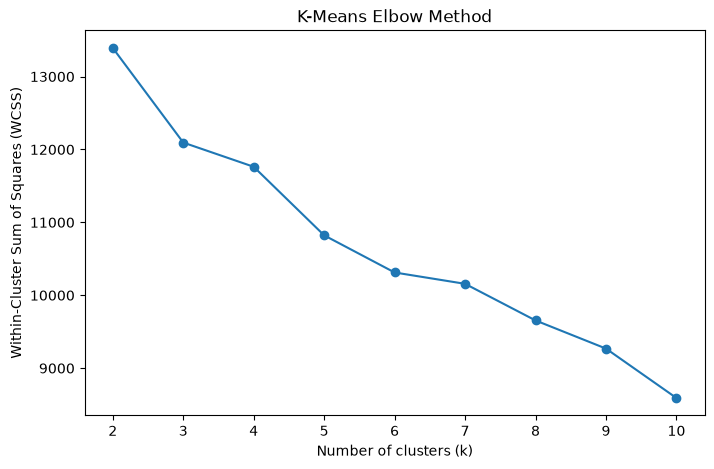

In [101]:
plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_results["k"],
    kmeans_results["wcss"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("K-Means Elbow Method")

plt.xticks(kmeans_results["k"])

plt.show()

Final K Means Run

In [102]:
FINAL_K = 4

labels, centroids, iterations, runtime = kmeans(
    X,
    k=FINAL_K,
    max_iterations=100,
    tolerance=1e-6,
    random_state=42
)

final_wcss = calculate_wcss(
    X,
    labels,
    centroids
)

print("Final K-Means Model")
print("--------------------")
print(f"k: {FINAL_K}")
print(f"Iterations: {iterations}")
print(f"Runtime: {runtime:.4f} seconds")
print(f"WCSS: {final_wcss:.6f}")

unique_clusters, cluster_sizes = np.unique(
    labels,
    return_counts=True
)

print("\nCluster sizes:")

for cluster_id, size in zip(unique_clusters, cluster_sizes):
    print(f"Cluster {cluster_id}: {size:,} users")

print(f"\nTotal users clustered: {len(labels):,}")

Final K-Means Model
--------------------
k: 4
Iterations: 100
Runtime: 15.0982 seconds
WCSS: 11762.294361

Cluster sizes:
Cluster 0: 68,298 users
Cluster 1: 31,544 users
Cluster 2: 104,652 users
Cluster 3: 1,715 users

Total users clustered: 206,209


Add cluster assignments to dataframe

In [103]:
user_features_clustered = user_features.copy()

user_features_clustered["cluster"] = labels

user_features_clustered.head()

,user_id,alcohol,babies,bakery,beverages,breakfast,bulk,canned_goods,dairy_eggs,deli,...,household,international,meat_seafood,other,pantry,personal_care,pets,produce,snacks,cluster
0,1,0.000000,0.0,0.000000,0.111111,0.055556,0.0,0.000000,0.277778,0.000000,...,0.055556,0.000000,0.000000,0.0,0.055556,0.000000,0.0,0.222222,0.222222,2
1,2,0.000000,0.0,0.019608,0.058824,0.029412,0.0,0.009804,0.176471,0.117647,...,0.000000,0.019608,0.009804,0.0,0.068627,0.009804,0.0,0.156863,0.205882,2
2,3,0.000000,0.0,0.000000,0.060606,0.000000,0.0,0.000000,0.181818,0.030303,...,0.030303,0.000000,0.000000,0.0,0.060606,0.000000,0.0,0.363636,0.151515,0
3,4,0.117647,0.0,0.117647,0.176471,0.000000,0.0,0.058824,0.000000,0.117647,...,0.117647,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.117647,0.058824,1
4,5,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.043478,0.173913,0.043478,...,0.000000,0.043478,0.000000,0.0,0.086957,0.000000,0.0,0.434783,0.043478,0


Save final centroids

In [104]:
centroid_df = pd.DataFrame(
    centroids,
    columns=feature_columns
)

centroid_df.index.name = "cluster"

centroid_df

,alcohol,babies,bakery,beverages,breakfast,bulk,canned_goods,dairy_eggs,deli,dry_goods_pasta,frozen,household,international,meat_seafood,other,pantry,personal_care,pets,produce,snacks
cluster,,,,,,,,,,,,,,,,,,,,
0,0.001611,0.005528,0.025615,0.050966,0.015291,0.001534,0.038545,0.121526,0.027666,0.026415,0.051459,0.016508,0.009827,0.024310,0.001010,0.071687,0.011370,0.000811,0.438284,0.060036
1,0.008348,0.006667,0.027435,0.210385,0.032059,0.000847,0.017616,0.098359,0.023982,0.014345,0.060413,0.088764,0.006052,0.010728,0.002691,0.060093,0.046875,0.005405,0.078088,0.200847
2,0.004851,0.013515,0.039030,0.066639,0.026473,0.000805,0.044647,0.158116,0.034342,0.038019,0.094485,0.034917,0.012160,0.025225,0.001629,0.096850,0.023750,0.003662,0.196145,0.084740
3,0.438905,0.002794,0.019699,0.114261,0.011028,0.000175,0.011046,0.059637,0.018634,0.007899,0.037557,0.043509,0.004453,0.008181,0.007212,0.044549,0.013642,0.002604,0.077410,0.076804


Largest centroid value

In [105]:
for cluster_id in range(FINAL_K):
    
    print(f"\nCluster {cluster_id}")
    print("--------------------")
    
    top_departments = (
        centroid_df
        .loc[cluster_id]
        .sort_values(ascending=False)
        .head(5)
    )
    
    print(top_departments)


Cluster 0
--------------------
produce       0.438284
dairy_eggs    0.121526
pantry        0.071687
snacks        0.060036
frozen        0.051459
Name: 0, dtype: float64

Cluster 1
--------------------
beverages     0.210385
snacks        0.200847
dairy_eggs    0.098359
household     0.088764
produce       0.078088
Name: 1, dtype: float64

Cluster 2
--------------------
produce       0.196145
dairy_eggs    0.158116
pantry        0.096850
frozen        0.094485
snacks        0.084740
Name: 2, dtype: float64

Cluster 3
--------------------
alcohol       0.438905
beverages     0.114261
produce       0.077410
snacks        0.076804
dairy_eggs    0.059637
Name: 3, dtype: float64
